# Economic Development & Life Expectancy — Analysis Notebook

This notebook walks through the analysis step by step. It calls the same functions as the scripts in `src/`, so the numbers here match `reports/tables/` exactly.

**Data:** World Bank WDI via the official API: `NY.GDP.PCAP.PP.KD` (GDP per capita, PPP, constant 2021 int'l $) and `SP.DYN.LE00.IN` (life expectancy at birth, years).
**Design:** observational, ecological (country-level). Nothing here identifies a causal effect.

By default the notebook reads the raw files already saved in `data/raw/`. Set `REFRESH = True` to download fresh data from the API first. Fresh data may differ if the World Bank has revised the series.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
import download_data, clean_data, statistical_analysis as sa, make_figures
pd.set_option("display.precision", 3); pd.set_option("display.width", 140)
REFRESH = False

## 1. Data acquisition and provenance

In [2]:
if REFRESH:
    download_data.main()
manifest = json.loads((ROOT / "data/raw/download_manifest.json").read_text(encoding="utf-8"))
meta = json.loads((ROOT / "data/raw/indicator_metadata.json").read_text(encoding="utf-8"))
print("Retrieved (UTC):", manifest["retrieved_at_utc"])
for f, v in manifest["files"].items():
    print(f, {k: v.get(k) for k in ("records", "api_total", "api_lastupdated")})
for code_, m in meta.items():
    print(f"\n{code_}: {m['IndicatorName']} | unit: {m['Unitofmeasure']} | licence: {m['License_Type']}")

Retrieved (UTC): 2026-11-10T13:46:55+00:00
NY.GDP.PCAP.PP.KD.json {'records': 6916, 'api_total': 6916, 'api_lastupdated': '2026-10-08'}
SP.DYN.LE00.IN.json {'records': 6916, 'api_total': 6916, 'api_lastupdated': '2026-10-08'}
countries.json {'records': 296, 'api_total': None, 'api_lastupdated': None}
indicator_metadata.json {'records': None, 'api_total': None, 'api_lastupdated': None}

NY.GDP.PCAP.PP.KD: GDP per capita, PPP (constant 2021 international $) | unit: Constant 2021 international $ | licence: CC BY-4.0

SP.DYN.LE00.IN: Life expectancy at birth, total (years) | unit: Years | licence: CC BY-4.0


## 2. Cleaning, merging and the exclusion log

In [3]:
log = clean_data.main()
panel = sa.load_panel()
panel.dtypes

{
 "year_window": [
  2000,
  2024
 ],
 "entities_total": 296,
 "aggregates": 79,
 "economies": 217,
 "gdp_raw_records": 6916,
 "gdp_blank_iso3_records": 130,
 "gdp_duplicate_rows_dropped": 0,
 "gdp_aggregate_records_removed": 1274,
 "gdp_records_outside_window": 217,
 "gdp_nonmissing_outside_window": 185,
 "le_raw_records": 6916,
 "le_blank_iso3_records": 130,
 "le_duplicate_rows_dropped": 0,
 "le_aggregate_records_removed": 1274,
 "le_records_outside_window": 217,
 "le_nonmissing_outside_window": 0,
 "panel_rows": 5425,
 "exclusion_counts": {
  "included": 4916,
  "missing_gdp": 509
 },
 "analysis_rows": 4916,
 "analysis_economies": 199,
 "economies_never_usable": [
  "American Samoa",
  "British Virgin Islands",
  "Channel Islands",
  "Cuba",
  "Eritrea",
  "French Polynesia",
  "Gibraltar",
  "Guam",
  "Isle of Man",
  "Korea, Dem. People's Rep.",
  "Liechtenstein",
  "Monaco",
  "New Caledonia",
  "Northern Mariana Islands",
  "South Sudan",
  "St. Martin (French part)",
  "Venezu

iso3                      str
name                      str
region                    str
income_level              str
year                    int64
gdp_pc_ppp            float64
log_gdp_pc            float64
life_expectancy       float64
missing_gdp              bool
missing_le               bool
nonpositive_gdp          bool
invalid_le               bool
le_extreme_low           bool
le_transient_shock       bool
exclusion_reason          str
in_analysis              bool
dtype: object

In [4]:
print("Exclusion reasons (economy-years, 2000-2024):", log["exclusion_counts"])
print("Economies never usable:", len(log["economies_never_usable"]))
print(log["economies_never_usable"])

Exclusion reasons (economy-years, 2000-2024): {'included': 4916, 'missing_gdp': 509}
Economies never usable: 18
['American Samoa', 'British Virgin Islands', 'Channel Islands', 'Cuba', 'Eritrea', 'French Polynesia', 'Gibraltar', 'Guam', 'Isle of Man', "Korea, Dem. People's Rep.", 'Liechtenstein', 'Monaco', 'New Caledonia', 'Northern Mariana Islands', 'South Sudan', 'St. Martin (French part)', 'Venezuela, RB', 'Yemen, Rep.']


In [5]:
pd.read_csv(ROOT / "data/processed/coverage_by_year.csv").set_index("year").T

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
economies,217,217,217,217,217,217,217,217,217,217,...,217,217,217,217,217,217,217,217,217,217
with_gdp,192,192,193,193,193,193,194,195,197,198,...,199,199,199,199,199,199,199,199,197,195
with_le,217,217,217,217,217,217,217,217,217,217,...,217,217,217,217,217,217,217,217,217,217
usable,192,192,193,193,193,193,194,195,197,198,...,199,199,199,199,199,199,199,199,197,195


In [6]:
flags = panel[panel.le_extreme_low | panel.le_transient_shock][["iso3","year","life_expectancy","gdp_pc_ppp","in_analysis"]]
flags  # flagged values are kept; the sensitivity analyses drop them

,iso3,year,life_expectancy,gdp_pc_ppp,in_analysis
784,CAF,2009,14.665,1402.682,True
789,CAF,2014,40.265,1001.856,True
792,CAF,2017,45.231,1103.866,True
793,CAF,2018,52.297,1125.701,True
794,CAF,2019,31.530,1145.096,True
795,CAF,2020,50.596,1136.571,True
796,CAF,2021,40.279,1128.552,True
797,CAF,2022,18.818,1136.802,True
2135,HTI,2010,45.577,3176.509,True
3258,MMR,2008,56.364,3254.739,True


## 3. Exploratory analysis

In [7]:
results = sa.run_all()
make_figures.main()
Y = results["primary_year"]
results["descriptives"].set_index(["year", "variable"])

Figures written to figures/


n       mean         sd       min        q1     median         q3         max  skewness  \
year             variable                                                                                                        
2000             gdp_pc_ppp        192.0  19141.362  22362.143   702.850  3818.614  10588.778  23097.939  114148.354     1.873   
                 log_gdp_pc        192.0      9.200      1.215     6.555     8.248      9.267     10.046      11.645    -0.045   
                 life_expectancy   192.0     67.021      9.651    44.834    61.166     70.058     73.937      81.863    -0.658   
2010             gdp_pc_ppp        198.0  23633.983  25414.222   988.019  4890.005  14101.030  33945.375  132502.282     1.874   
                 log_gdp_pc        198.0      9.475      1.179     6.896     8.495      9.554     10.432      11.794    -0.194   
                 life_expectancy   198.0     70.403      8.807    45.577    64.552     72.352     76.742      84.197    -0.724   
2019             gdp_pc_ppp        199.0  26352.946  26295.479  1054.726  6337.894  16761.123  38237.005  133453.896     1.616   
                 log_gdp_pc        199.0      9.634      1.142     6.961     8.754      9.727     10.552      11.802    -0.293   
                 life_expectancy   199.0     72.723      7.993    31.530    66.869     73.764     78.413      85.257    -0.952   
2023             gdp_pc_ppp        197.0  27404.733  26991.486  1033.009  6520.899  17685.859  41320.258  130296.844     1.495   
                 log_gdp_pc        197.0      9.665      1.160     6.940     8.783      9.781     10.629      11.778    -0.329   
                 life_expectancy   197.0     73.474      7.094    54.462    67.689     74.402     78.473      85.706    -0.363   
2000-2024 pooled gdp_pc_ppp       4916.0  23872.931  25404.362   702.850  5124.414  14329.181  35297.471  174569.523     1.769   
                 log_gdp_pc       4916.0      9.482      1.184     6.555     8.542      9.570     10.472      12.070    -0.209   
                 life_expectancy  4916.0     70.637      8.741    14.665    65.165     72.123     77.136      85.708    -0.780   

                                  excess_kurtosis  
year             variable                          
2000             gdp_pc_ppp                 3.524  
                 log_gdp_pc                -0.829  
                 life_expectancy           -0.593  
2010             gdp_pc_ppp                 4.210  
                 log_gdp_pc                -0.859  
                 life_expectancy           -0.124  
2019             gdp_pc_ppp                 2.893  
                 log_gdp_pc                -0.789  
                 life_expectancy            2.408  
2023             gdp_pc_ppp                 2.245  
                 log_gdp_pc                -0.797  
                 life_expectancy           -0.659  
2000-2024 pooled gdp_pc_ppp                 3.623  
                 log_gdp_pc                -0.849  
                 life_expectancy            0.543

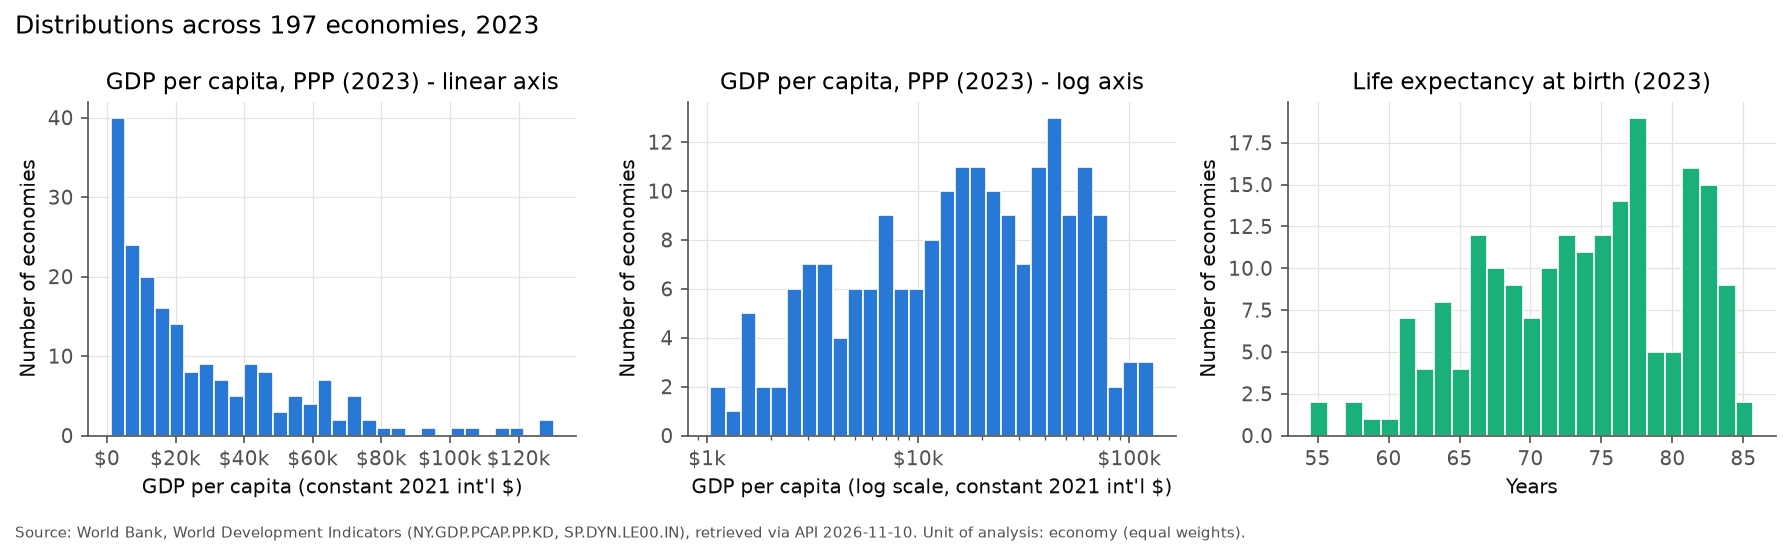

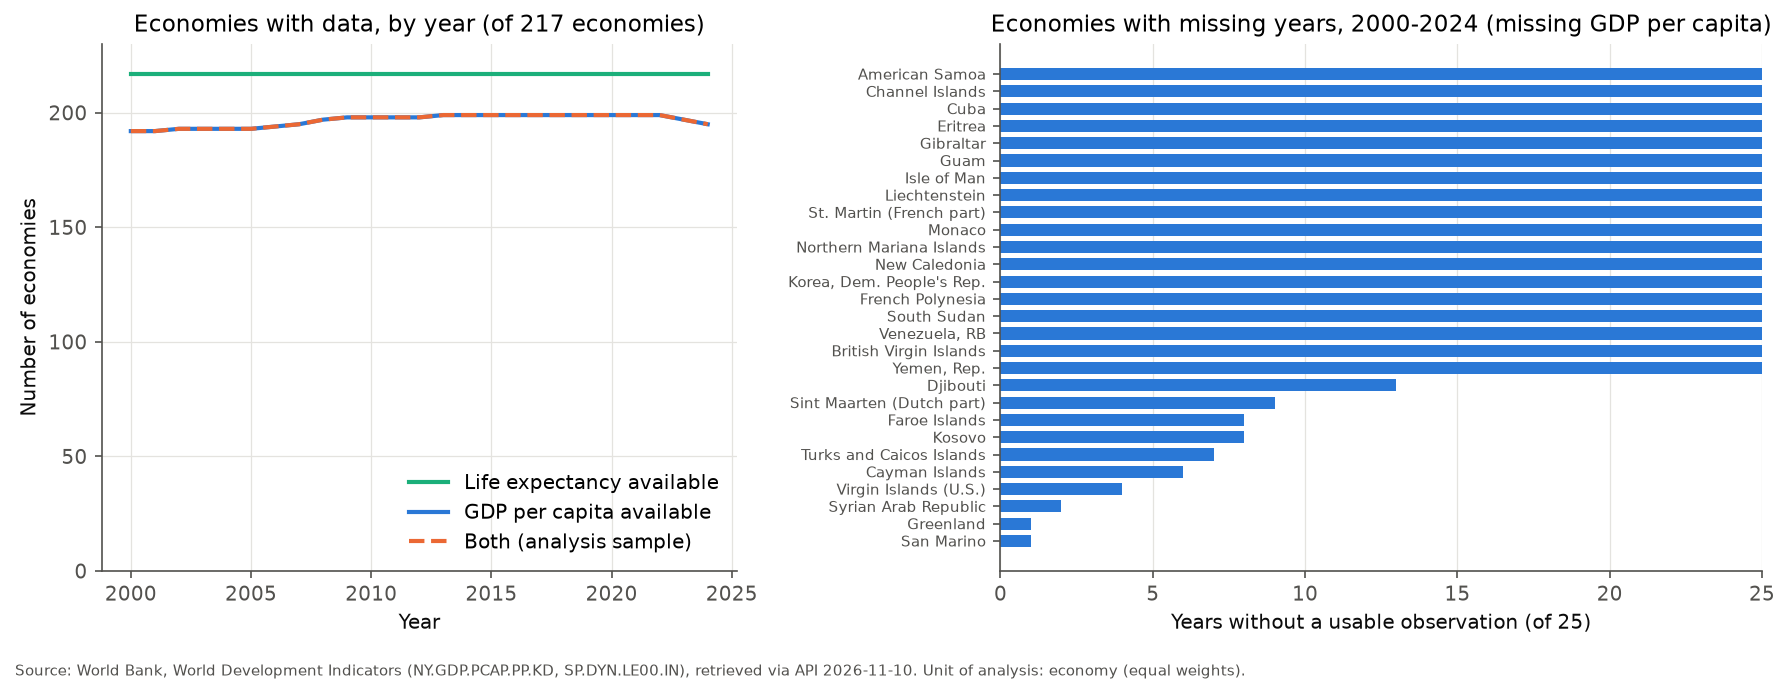

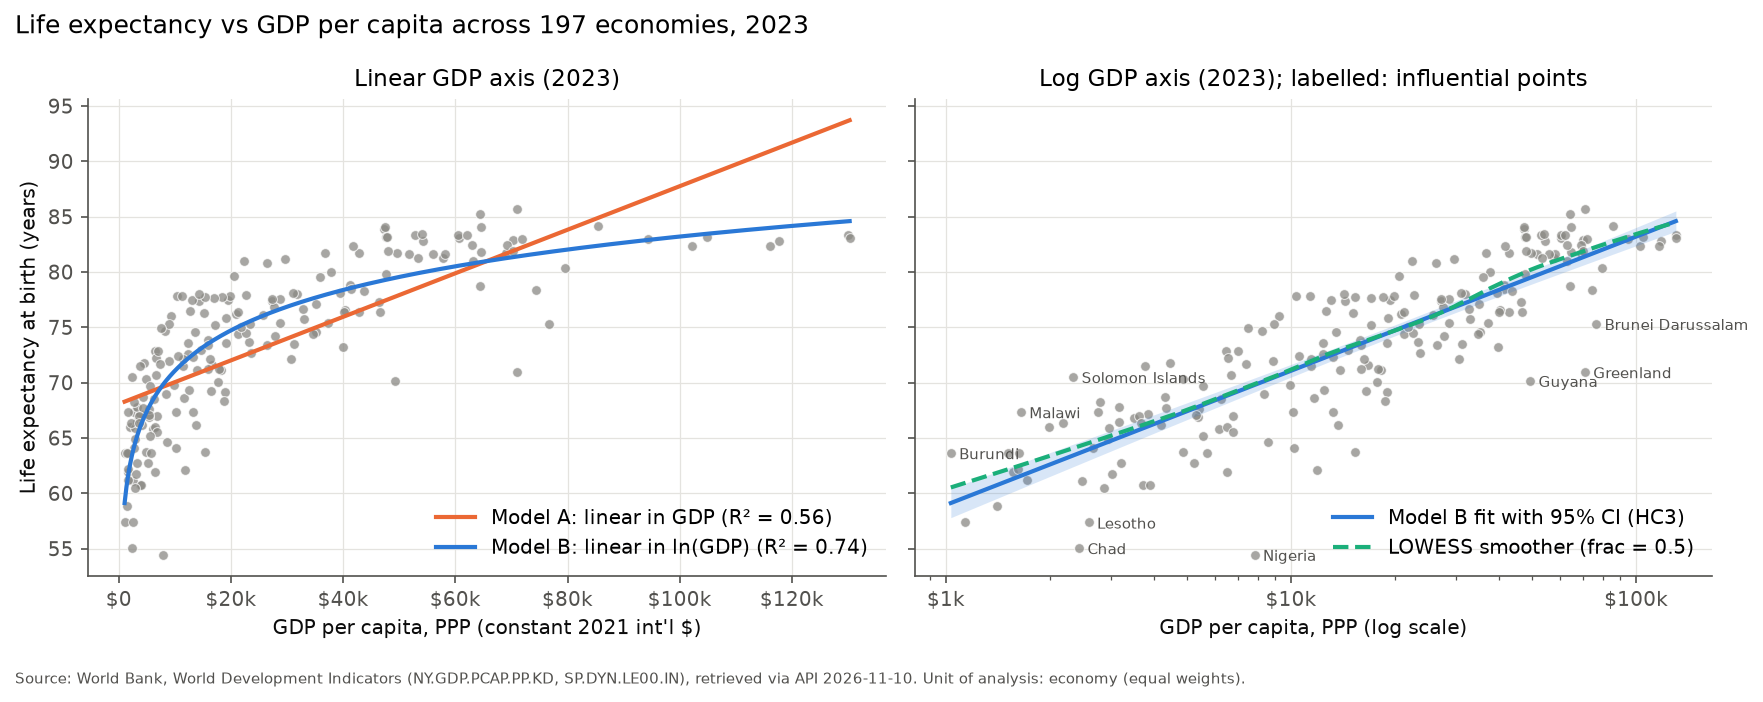

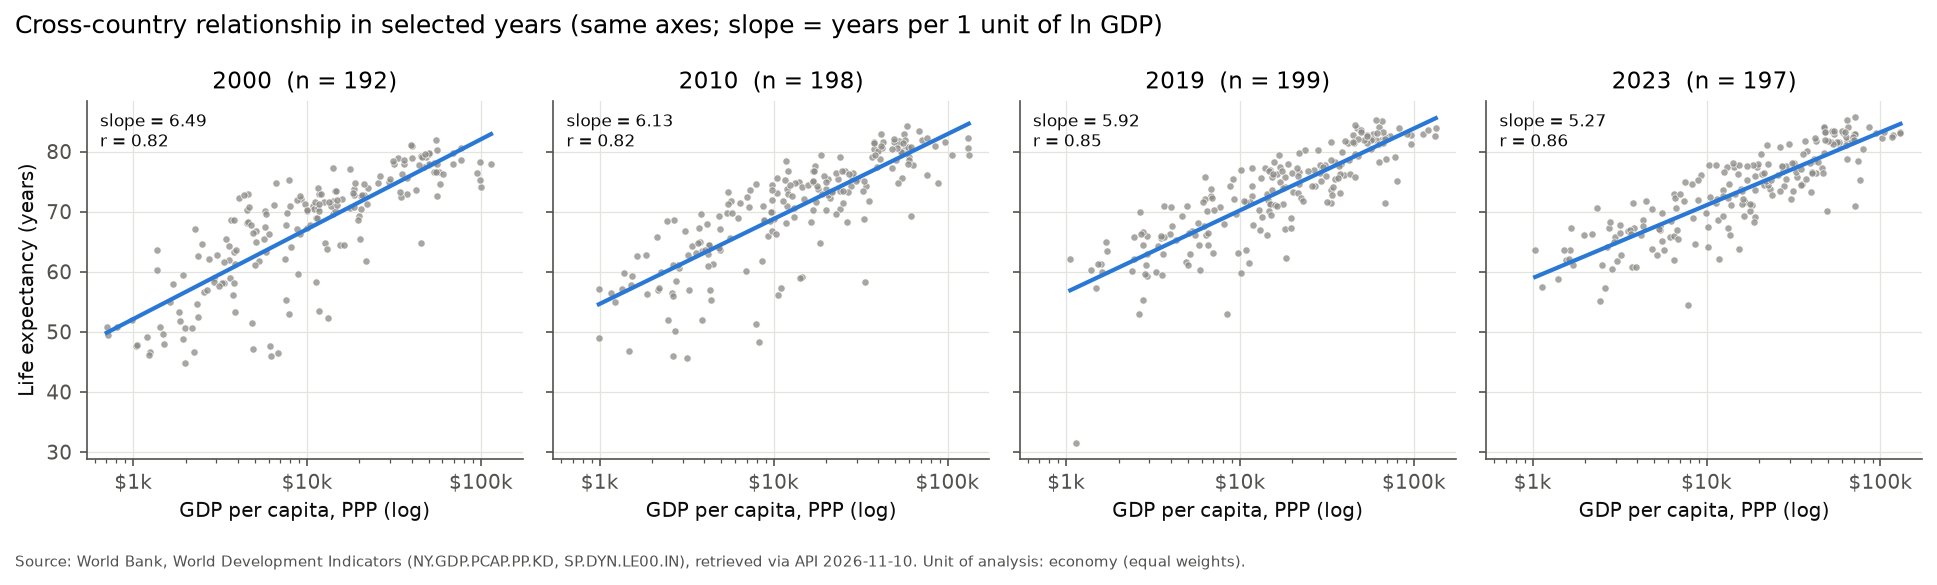

In [8]:
for f in ["fig01_distributions.png", "fig02_data_coverage.png", "fig03_scatter_linear_vs_log.png", "fig04_selected_years.png"]:
    display(Image(filename=str(ROOT / "figures" / f)))

## 4. Correlation

In [9]:
pd.DataFrame(results["correlations"]).T[["n","pearson_r","pearson_ci","spearman_rho","spearman_ci"]]

,n,pearson_r,pearson_ci,spearman_rho,spearman_ci
gdp_level,197,0.749,"(0.68, 0.804)",0.872,"(0.827, 0.907)"
log_gdp,197,0.861,"(0.82, 0.894)",0.872,"(0.827, 0.907)"


Spearman's ρ depends only on ranks, so it is the same for GDP and ln(GDP). Pearson's r rises sharply after the log transform, which shows that the relationship is monotone but not linear in levels.

## 5. Regression: Model A vs Model B (same sample)

In [10]:
pd.read_csv(ROOT / f"reports/tables/regression_models_{Y}.csv").set_index("model").T

model,A_linear,B_log,C_log_quadratic
n,1.970e+02,1.970e+02,1.970e+02
r2,5.604e-01,7.419e-01,7.430e-01
adj_r2,5.581e-01,7.406e-01,7.404e-01
aic,1.172e+03,1.067e+03,1.068e+03
bic,1.179e+03,1.074e+03,1.078e+03
rmse,4.716e+00,3.613e+00,3.615e+00
Intercept_coef,6.808e+01,2.257e+01,7.325e+01
gdp_k_coef,1.968e-01,NaN,NaN
Intercept_ci_low,6.697e+01,1.845e+01,7.251e+01
gdp_k_ci_low,1.618e-01,NaN,NaN


In [11]:
print(results["interpretation_B"])
pd.DataFrame(results["model_C_local_slopes"])

{'years_per_10pct_gdp': np.float64(0.5020152471583335), 'years_per_doubling_gdp': np.float64(3.6509264160480908)}


,gdp_pc_ppp,slope_per_log_unit,years_per_10pct
0,2000,4.639,0.442
1,5000,4.946,0.471
2,10000,5.178,0.494
3,20000,5.410,0.516
4,50000,5.718,0.545
5,100000,5.950,0.567


## 6. Diagnostics and influential observations

In [12]:
pd.DataFrame({k: {kk: (vv if not isinstance(vv, dict) else {a: round(b, 4) for a, b in vv.items()})
                    for kk, vv in v.items() if kk not in ("flagged", "thresholds")}
              for k, v in results["diagnostics"].items()})

,A_linear,B_log
breusch_pagan,"{'lm': 0.754, 'p': 0.3852}","{'lm': 1.9767, 'p': 0.1597}"
white,"{'lm': 27.1426, 'p': 0.0}","{'lm': 3.7967, 'p': 0.1498}"
jarque_bera,"{'stat': 13.5931, 'p': 0.0011, 'skew': -0.6433...","{'stat': 35.3778, 'p': 0.0, 'skew': -0.8165, '..."
shapiro_wilk,"{'W': 0.9665, 'p': 0.0001}","{'W': 0.964, 'p': 0.0001}"
reset_power2,"{'F': 91.1303, 'p': 0.0}","{'F': 0.8251, 'p': 0.3648}"
reset_power3,"{'F': 62.8492, 'p': 0.0}","{'F': 1.562, 'p': 0.2124}"


In [13]:
display(results["influential_B"])
results["influence_sensitivity"]

,iso3,cooks_d,leverage,student_resid,max_abs_dfbeta,name,gdp_pc_ppp,life_expectancy
0,NGA,0.063,0.007,-4.461,0.229,Nigeria,7843.004,54.462
1,GRL,0.059,0.014,-2.965,0.277,Greenland,71037.537,70.972
2,TCD,0.053,0.018,-2.423,0.300,Chad,2433.533,55.069
3,SLB,0.038,0.019,1.999,0.252,Solomon Islands,2339.875,70.528
4,GUY,0.034,0.010,-2.627,0.185,Guyana,49312.360,70.180
5,MWI,0.033,0.024,1.622,0.241,Malawi,1649.299,67.353
6,LSO,0.030,0.017,-1.852,0.222,Lesotho,2592.457,57.375
7,BDI,0.028,0.033,1.277,0.227,Burundi,1033.009,63.651
8,BRN,0.024,0.015,-1.817,0.178,Brunei Darussalam,76616.701,75.327


{'full': {'n': 197,
  'slope': np.float64(5.267173435083097),
  'ci': (4.854257461753209, 5.680089408412986),
  'r2': np.float64(0.7419131339244163)},
 'without_influential': {'n': 188,
  'dropped': ['NGA', 'GRL', 'TCD', 'SLB', 'GUY', 'MWI', 'LSO', 'BDI', 'BRN'],
  'slope': np.float64(5.418372818879795),
  'ci': (5.086925436428691, 5.749820201330898),
  'r2': np.float64(0.7889218900143539)},
 'huber_rlm': {'n': 197,
  'slope': np.float64(5.263767946160417),
  'ci': (4.844928030386145, 5.68260786193469)}}

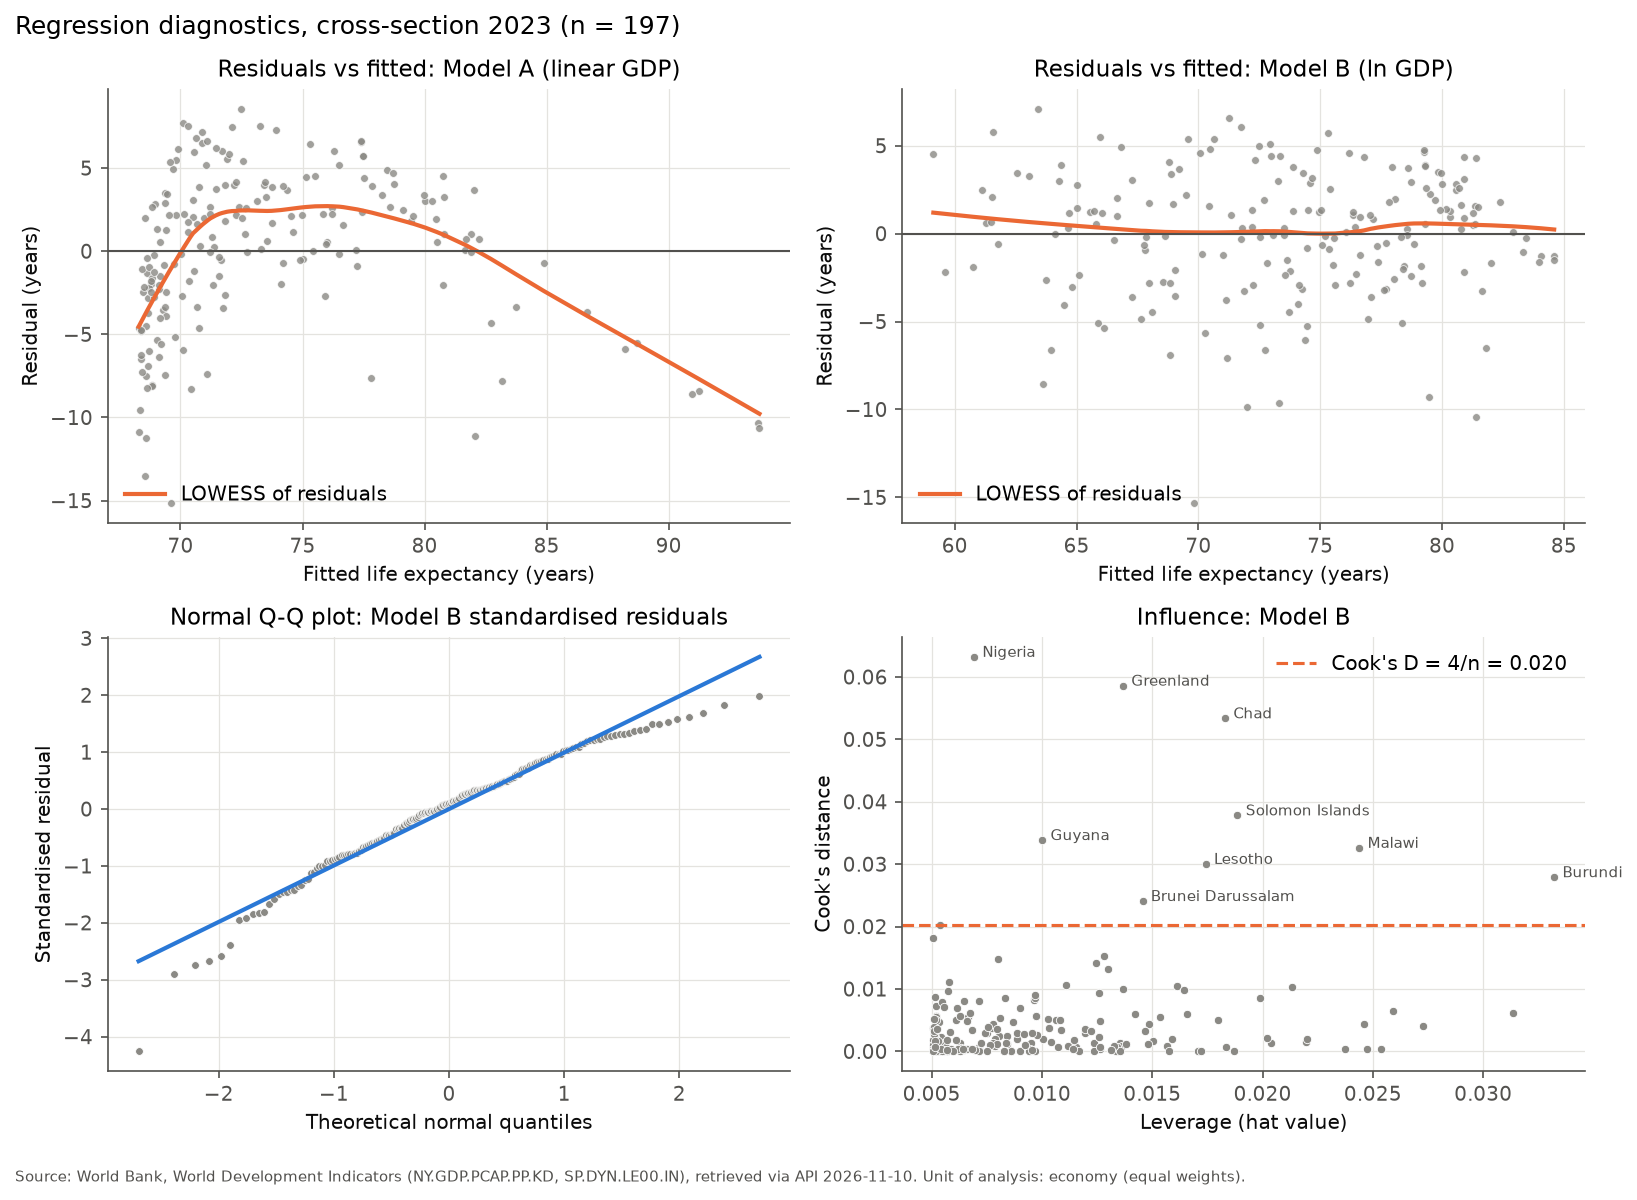

In [14]:
display(Image(filename=str(ROOT / "figures/fig05_regression_diagnostics.png")))

## 7. Over time: cross-sections vs within-country change

In [15]:
display(results["yearly"].round(3))
results["slope_trend"]

,year,n,pearson_raw,pearson_log,spearman,slope_B,slope_B_ci_low,slope_B_ci_high,r2_A,r2_B,mean_le,median_gdp
0,2000,192,0.638,0.818,0.849,6.493,5.933,7.054,0.407,0.668,67.021,10588.778
1,2001,192,0.637,0.811,0.845,6.455,5.895,7.014,0.406,0.657,67.349,10907.293
2,2002,193,0.643,0.808,0.844,6.384,5.833,6.936,0.414,0.653,67.677,11144.051
3,2003,193,0.645,0.809,0.844,6.314,5.774,6.854,0.416,0.655,67.960,11183.291
4,2004,193,0.649,0.810,0.848,6.262,5.726,6.798,0.422,0.656,68.290,11607.938
5,2005,193,0.652,0.808,0.844,6.176,5.647,6.706,0.425,0.653,68.622,12022.508
6,2006,194,0.650,0.809,0.844,6.046,5.520,6.572,0.423,0.654,69.003,12982.800
7,2007,195,0.657,0.813,0.849,5.982,5.462,6.502,0.432,0.662,69.360,13754.921
8,2008,197,0.667,0.818,0.851,6.001,5.481,6.522,0.445,0.670,69.761,14030.141
9,2009,198,0.636,0.793,0.853,6.320,5.481,7.159,0.404,0.629,69.969,13655.268


{'all': {'slope_2000': np.float64(6.462541690931458),
  'change_per_year': np.float64(-0.04079094662619406),
  'ci_low': np.float64(-0.06445889196974922),
  'ci_high': np.float64(-0.017123001282638918),
  'p': np.float64(0.0007303228160013134),
  'n_obs': 4916,
  'n_countries': 199},
 'balanced': {'slope_2000': np.float64(6.556324729371174),
  'change_per_year': np.float64(-0.04249714267235107),
  'ci_low': np.float64(-0.06676322766103421),
  'ci_high': np.float64(-0.01823105768366794),
  'p': np.float64(0.0005980863854179504),
  'n_obs': 4725,
  'n_countries': 189}}

In [16]:
display(results["panel_models"].round(3))
pd.DataFrame(results["long_differences"]).round(3)

,model,slope,se,ci_low,ci_high,p,n_obs,n_countries,inference,sample
0,pooled_ols,6.093,0.239,5.624,6.562,0.000,4916,199,cluster(country),all 2000-2024
1,pooled_ols_year_fe,5.984,0.243,5.509,6.460,0.000,4916,199,cluster(country),all 2000-2024
2,between_country_means,6.056,0.248,5.570,6.541,0.000,199,199,HC3,all 2000-2024
3,country_fe,7.051,0.534,6.004,8.097,0.000,4916,199,cluster(country),all 2000-2024
4,twoway_fe,1.549,0.539,0.494,2.605,0.004,4916,199,cluster(country),all 2000-2024
5,pooled_ols,6.143,0.239,5.674,6.612,0.000,4319,199,cluster(country),excl. 2020-2022
6,pooled_ols_year_fe,6.032,0.242,5.558,6.506,0.000,4319,199,cluster(country),excl. 2020-2022
7,between_country_means,6.094,0.247,5.610,6.578,0.000,199,199,HC3,excl. 2020-2022
8,country_fe,7.478,0.536,6.428,8.527,0.000,4319,199,cluster(country),excl. 2020-2022
9,twoway_fe,1.604,0.571,0.486,2.722,0.005,4319,199,cluster(country),excl. 2020-2022


,window,n,mean_d_le,mean_d_log_gdp,share_le_increased,slope,ci_low,ci_high,p,intercept,r2,pearson_r,spearman_rho,spearman_p,slope_ctrl_le_start,ci_ctrl_low,ci_ctrl_high,p_ctrl,coef_le_start
0,2000-2019,192,5.561,0.409,0.979,2.246,0.586,3.906,0.008,4.642,0.042,0.205,0.223,0.002,1.636,0.043,3.229,0.044,-0.227
1,2000-2023,191,6.364,0.443,0.984,1.267,-0.151,2.686,0.080,5.802,0.015,0.121,0.161,0.026,0.906,-0.008,1.821,0.052,-0.320


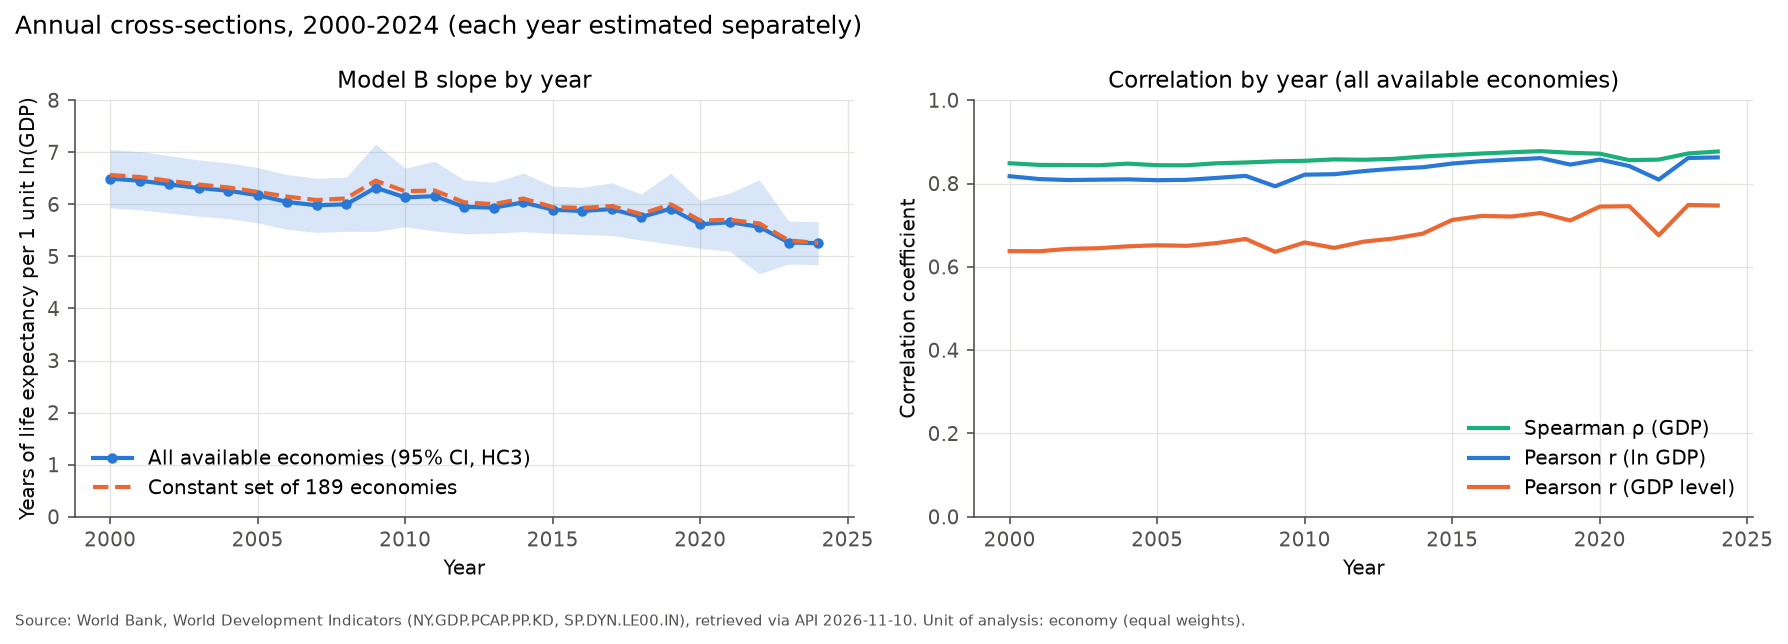

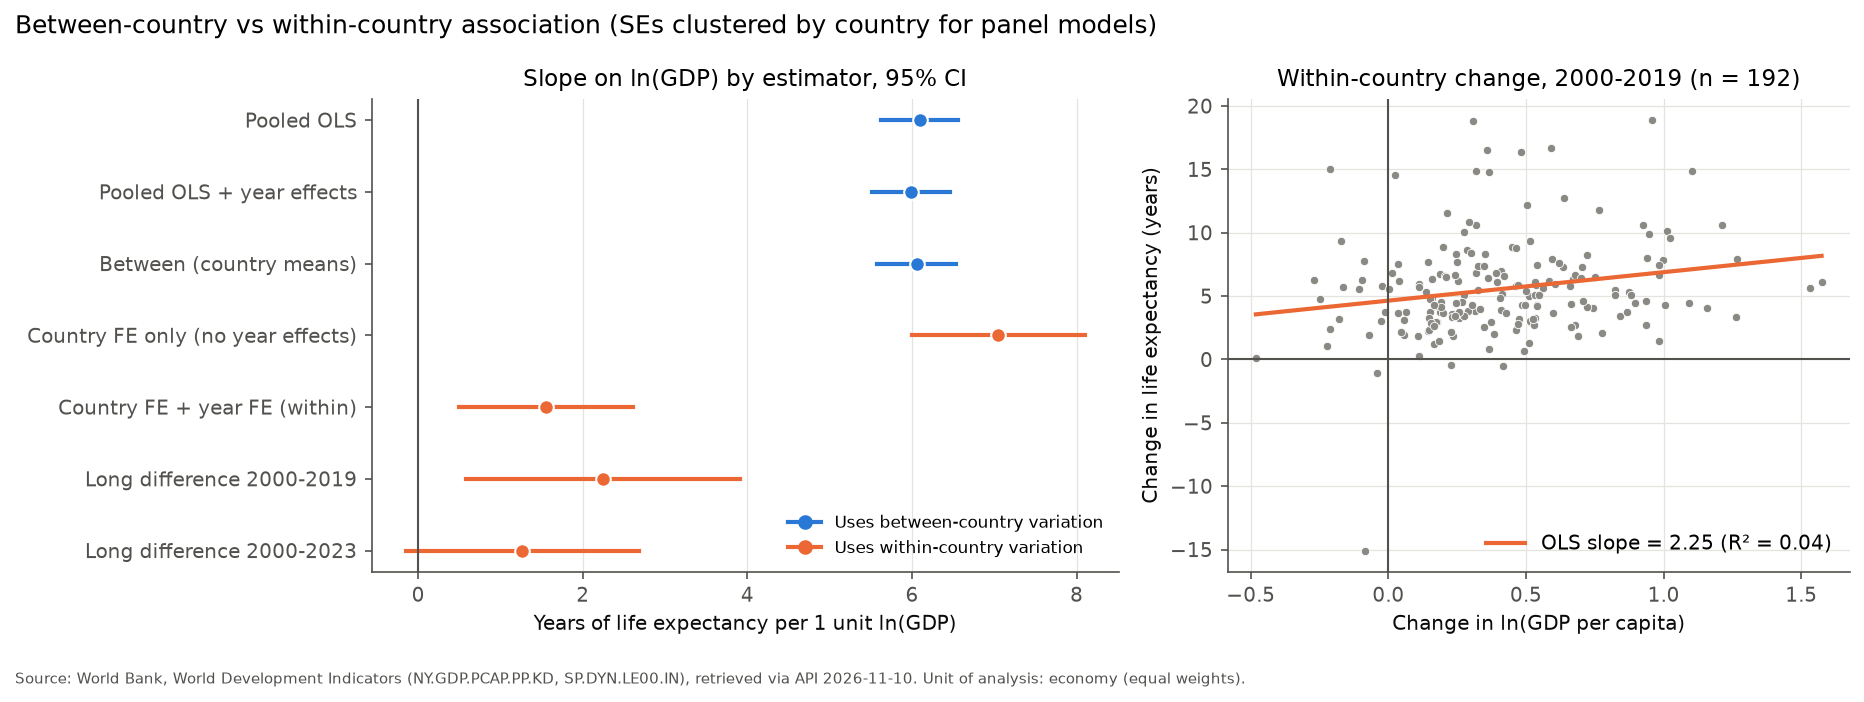

In [17]:
for f in ["fig06_cross_sections_over_time.png", "fig07_between_vs_within.png"]:
    display(Image(filename=str(ROOT / "figures" / f)))

## 8. Summary

The interpretation, with all caveats, is in `reports/research_report_tr.md`. In brief: the cross-country association is strong and close to linear in ln(GDP). The association of within-country changes, net of common year effects, is much smaller and less precisely estimated. None of these estimates is causal.